<a href="https://colab.research.google.com/github/LuckyMayHedgehog/Machine-Learning-data-science/blob/main/06-svm-iris/ML_lab6_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

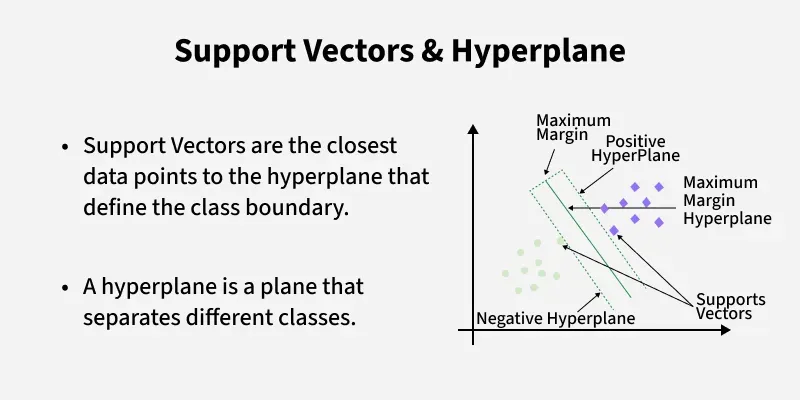

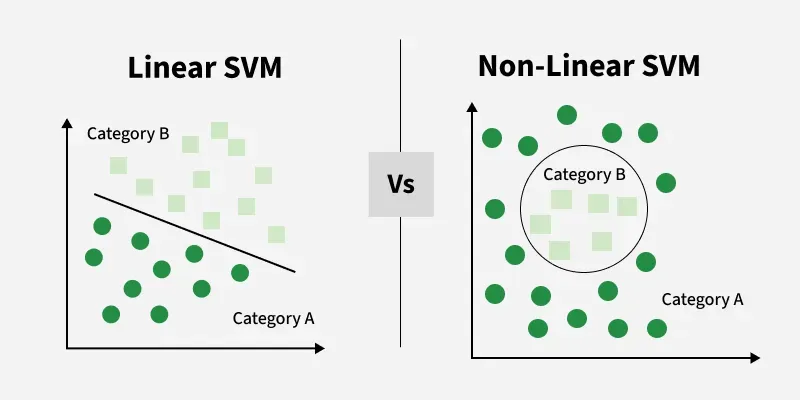

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification and regression tasks. It tries to find the best boundary known as hyperplane that separates different classes in the data. It is useful when you want to do binary classification like spam vs. not spam or cat vs. dog.

Support Vectors: The closest data points to the hyperplane, crucial for determining the hyperplane and margin in SVM.


Margin: The distance between the hyperplane and the support vectors. SVM aims to maximize this margin for better classification performance.

Не просто провести межу між класами, а провести її так, щоб вона була якомога далі від найближчих представників обох класів.

Linear Kernel: For linear separability.


Polynomial Kernel: Maps data into a polynomial space.

Radial Basis Function (RBF) Kernel: Transforms data into a space based on distances between data points.


https://youtu.be/_YPScrckx28?si=U6bXyUpzpx_PdrEZ

==========================================

Для набору даних https://www.kaggle.com/datasets/uciml/iris

1. Виконати застосування методу опорних векторів для класифікації

2. Виконати пошук оптимальних гіперпараметрів класифікатора за допомогою GridSearchCV та RandomizedSearchCV.

3. Визначити точність побудованої моделі за такими метриками: Confusion matrix, Accuracy, Precision, Recall, F1 Score, застосувати крос-валідацію.



Розмір навчальної вибірки: 105
Розмір тестової вибірки: 45

Базова Accuracy за замовчуванням: 0.9778

Запуск GridSearchCV
Найкращі параметри (GridSearchCV): {'svm__C': 100, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Найкраща оцінка на крос-валідації (CV Accuracy): 0.9714

Запуск RandomizedSearchCV
Найкращі параметри (RandomizedSearchCV): {'svm__C': np.float64(1.684721839352567), 'svm__gamma': np.float64(0.00023103940339194243), 'svm__kernel': 'linear'}
Найкраща оцінка на крос-валідації (CV Accuracy): 0.9714

ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ВІДКЛАДЕНІЙ ТЕСТОВІЙ ВИБІРЦІ
Accuracy:            0.9778
Precision (macro):   0.9792 | Precision (weighted): 0.9792
Recall (macro):      0.9778 | Recall (weighted):    0.9778
F1 Score (macro):    0.9778 | F1 Score (weighted):  0.9778

Детальний звіт класифікації (Classification Report):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica 

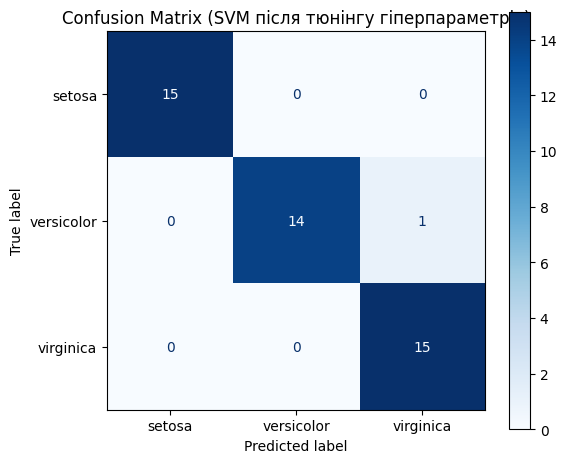

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import uniform, loguniform

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=13, stratify=y
)


print(f"Розмір навчальної вибірки: {X_train.shape[0]}")
print(f"Розмір тестової вибірки: {X_test.shape[0]}\n")

#pipeline - щоб не було data leakage, щоб воно не давало кращі результати (бо порахувало б тоді з тим, котрий забираємо)
base_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=13)) #Якщо ознаки будуть мати різні масштаби або різні одиниці вимірювання,
    #ознака з більшим числовим розкидом домінуватиме у формулі відстані
      #Ознака з більшими абсолютними значеннями штучно отримує значно більшу вагу

])


base_pipeline.fit(X_train, y_train)
y_pred_base = base_pipeline.predict(X_test)
print(f"Базова Accuracy за замовчуванням: {accuracy_score(y_test, y_pred_base):.4f}\n")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=13)
#В кожному з них 1:1:1 фолдів , 4 на навчання, 1 на тест, БАЛАНС


print("Запуск GridSearchCV")
grid_params = {
    'svm__C': [0.1, 1, 10, 100], #C - компроміс між помилками класифікації на навчальних даних і складністю межі, якою SVM розділяє класи
    'svm__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1], #Для RBF-ядра gamma впливає на те,
    #наскільки далеко від окремого навчального прикладу поширюється його вплив на межу класифікації.
    'svm__kernel': ['linear', 'rbf', 'poly']
}

'''
Маленьке C, наприклад 0.1, сильніше допускає помилки на навчальних даних, щоб модель могла побудувати більш узагальнену межу.

Більше C, наприклад 100, сильніше штрафує помилки на навчальних даних, тому модель намагатиметься класифікувати їх точніше.

Проте більше значення не означає автоматично кращу модель. Надмірно велике C може погіршити узагальнення на нових даних.

Мала gamma - Вплив окремих точок поширюється далі. Межа класифікації зазвичай виходить плавнішою.
______
kernel визначає тип ядра, яке SVM використовує для побудови межі між класами.

'linear'
Лінійне ядро. Будує лінійну межу: пряму на площині або гіперплощину в багатовимірному просторі.

'rbf'
Радіальне базисне ядро. Може формувати гнучкі нелінійні межі класифікації.

'poly'
Поліноміальне ядро. Дозволяє моделювати залежності за допомогою поліноміальних перетворень.
'''

grid_search = GridSearchCV(
    estimator=base_pipeline,
    param_grid=grid_params,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Найкращі параметри (GridSearchCV): {grid_search.best_params_}")
print(f"Найкраща оцінка на крос-валідації (CV Accuracy): {grid_search.best_score_:.4f}\n")




print("Запуск RandomizedSearchCV")
''' Логарифмічний розподіл допомагає досліджувати різні масштаби параметра, а не зосереджувати
    випадковий пошук переважно біля великих чисел лише через ширину числового діапазону.'''
random_params = {
    'svm__C': loguniform(1e-2, 1e2),          # неперервний логарифмічний розподіл від 0.01 до 100
    'svm__gamma': loguniform(1e-4, 1e1),      # неперервний розподіл від 0.0001 до 10
    'svm__kernel': ['linear', 'rbf', 'poly'],
}

random_search = RandomizedSearchCV(
    estimator=base_pipeline,
    param_distributions=random_params,
    n_iter=30,
    cv=cv_strategy,
    scoring='accuracy',
    random_state=13,
    n_jobs=-1
)
random_search.fit(X_train, y_train)

print(f"Найкращі параметри (RandomizedSearchCV): {random_search.best_params_}")
print(f"Найкраща оцінка на крос-валідації (CV Accuracy): {random_search.best_score_:.4f}\n")



best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ВІДКЛАДЕНІЙ ТЕСТОВІЙ ВИБІРЦІ")

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
prec_weighted = precision_score(y_test, y_pred, average='weighted')
rec_macro = recall_score(y_test, y_pred, average='macro')
rec_weighted = recall_score(y_test, y_pred, average='weighted')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy:            {acc:.4f}")
print(f"Precision (macro):   {prec_macro:.4f} | Precision (weighted): {prec_weighted:.4f}")
print(f"Recall (macro):      {rec_macro:.4f} | Recall (weighted):    {rec_weighted:.4f}")
print(f"F1 Score (macro):    {f1_macro:.4f} | F1 Score (weighted):  {f1_weighted:.4f}\n")

print("Детальний звіт класифікації (Classification Report):")
print(classification_report(y_test, y_pred, target_names=target_names))

cv_scores = cross_val_score(best_model, X, y, cv=cv_strategy, scoring='accuracy')
print(f"Крос-валідаційні оцінки моделі (5-fold): {np.round(cv_scores, 4)}")
print(f"Середня точність на CV: {cv_scores.mean():.4f} (± {cv_scores.std():.4f})\n")

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix (SVM після тюнінгу гіперпараметрів)")
plt.tight_layout()
plt.show()